# 20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed: benchmark



In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("benchmark")
from scipy.stats import spearmanr
from varsortability import calculate_varsortability
from condition_data import load_sample, sample_path


def sortability(frame, study):
    rows = []
    for family, seed in (
        frame[["dataset", "dataset_seed"]].drop_duplicates().itertuples(index=False, name=None)
    ):
        path = sample_path({"tuned": "evaluation"}.get(study, study), family)
        with load_sample(study, family, int(seed)) as data:
            raw = "X_raw" in data.files
            result = calculate_varsortability(data["X_raw"] if raw else data["X"], data["true_adj"])
            if not raw:
                for key in (
                    "varsortability",
                    "n_ordered_variance_paths",
                    "n_tied_variance_paths",
                ):
                    result[key] = np.nan
        rows.append(
            dict(
                dataset=family,
                dataset_seed=seed,
                study=study,
                raw_variance_available=raw,
                sample_path=str(path.relative_to(ROOT)),
                **result,
            )
        )
    return pd.DataFrame(rows)


In [2]:


output = ROOT / "results"
output.mkdir(parents=True, exist_ok=True)
sources = th.load_aligned_sources()
main = sources["benchmark_with_biological"]
complete = sources["complete"]
correlations = []
(output / "benchmark" / "by_family" / '20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed').mkdir(parents=True, exist_ok=True)


## Metrics, seed stability and sortability


,model,mean,std,size
0,AVICI,0.503411,0.042953,15
1,DAGMA_Linear,0.162224,0.063044,15
2,DAGMA_Nonlinear,0.331233,0.046755,15
3,DAS,0.303369,0.060568,15
4,DirectLiNGAM,0.375042,0.092327,15
5,FCI,0.164927,0.065919,15
6,GES,0.536679,0.149021,15
7,GOLEM,0.150139,0.062971,15
8,GRaSP,0.604832,0.095018,15
9,GraNDAG,0.061739,0.041395,15


,model,mean,std,size
0,AVICI,49.066667,10.996536,15
1,DAGMA_Linear,59.400000,8.449852,15
2,DAGMA_Nonlinear,52.213333,7.236512,15
3,DAS,73.200000,12.048711,15
4,DirectLiNGAM,68.333333,18.733723,15
5,FCI,54.262222,10.045214,15
6,GES,46.600000,17.087171,15
7,GOLEM,68.000000,11.850256,15
8,GRaSP,35.702222,9.969027,15
9,GraNDAG,55.933333,6.134989,15


,model,mean,std,size
0,AVICI,0.602429,0.104114,15
1,DAGMA_Linear,0.262201,0.117554,15
2,DAGMA_Nonlinear,0.450869,0.067551,15
3,DAS,0.277402,0.056788,15
4,DirectLiNGAM,0.336051,0.104202,15
5,FCI,0.834391,0.162682,15
6,GES,0.556505,0.178282,15
7,GOLEM,0.198536,0.079336,15
8,GRaSP,0.759608,0.116931,15
9,GraNDAG,0.547302,0.340484,15


,model,mean,std,size
0,AVICI,0.446927,0.071804,15
1,DAGMA_Linear,0.119508,0.045762,15
2,DAGMA_Nonlinear,0.264864,0.043560,15
3,DAS,0.337132,0.071990,15
4,DirectLiNGAM,0.434753,0.086552,15
5,FCI,0.092718,0.040590,15
6,GES,0.526702,0.140411,15
7,GOLEM,0.126996,0.062061,15
8,GRaSP,0.507916,0.091772,15
9,GraNDAG,0.033621,0.023215,15


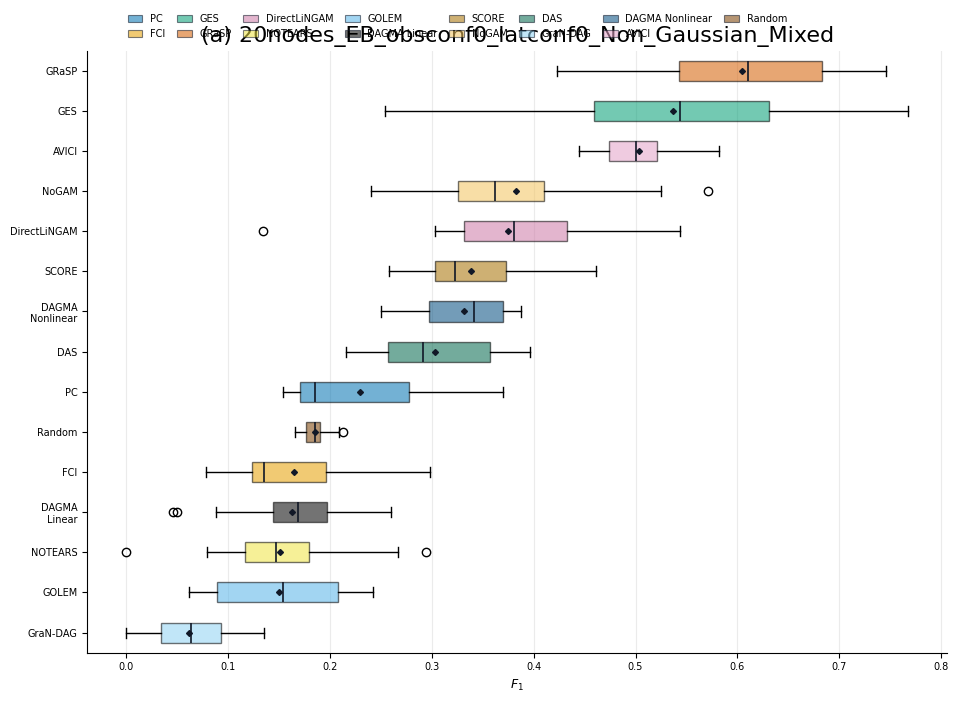

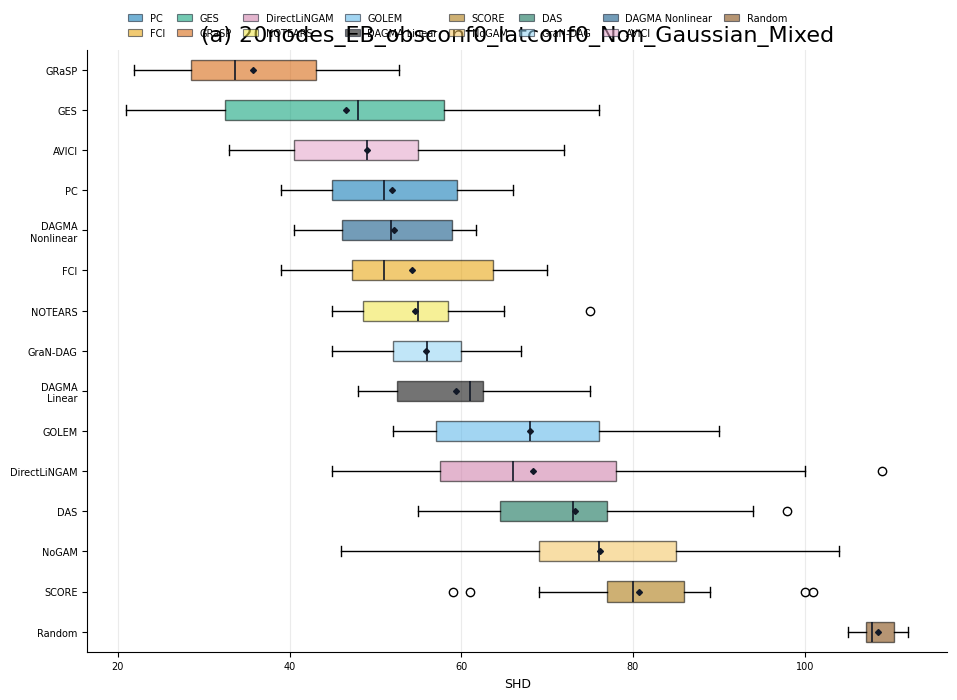

,dataset_seed,model,f1_range
0,13,AVICI,0.000000
1,13,DAGMA_Linear,0.000000
2,13,DAGMA_Nonlinear,0.203463
3,13,DAS,0.000000
4,13,DirectLiNGAM,0.000000
5,13,FCI,0.000000
6,13,GES,0.000000
7,13,GOLEM,0.000000
8,13,GRaSP,0.120716
9,13,GraNDAG,0.000000


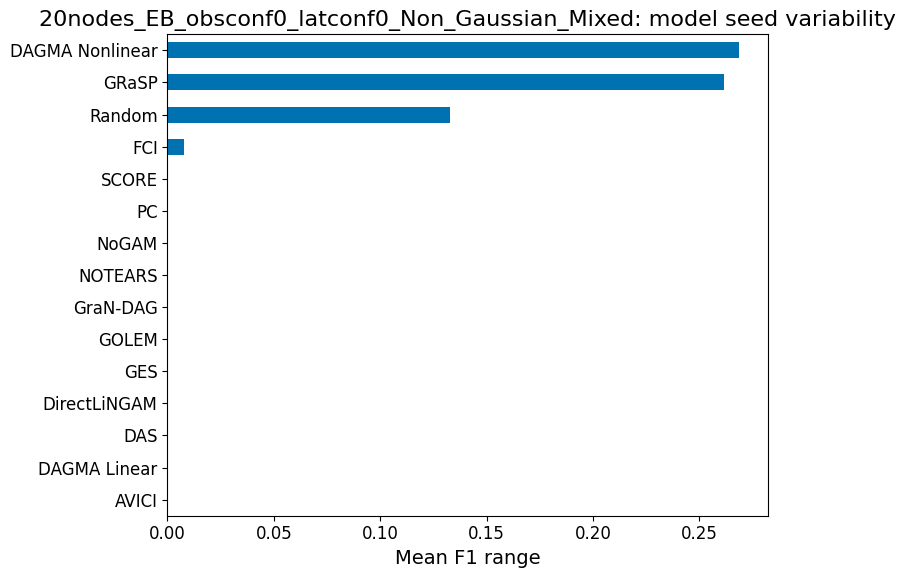

,model_seed,model,f1_range
0,0,AVICI,0.137834
1,0,DAGMA_Linear,0.213763
2,0,DAGMA_Nonlinear,0.255747
3,0,DAS,0.181636
4,0,DirectLiNGAM,0.409713
5,0,FCI,0.220076
6,0,GES,0.513889
7,0,GOLEM,0.180569
8,0,GRaSP,0.429553
9,0,GraNDAG,0.135135


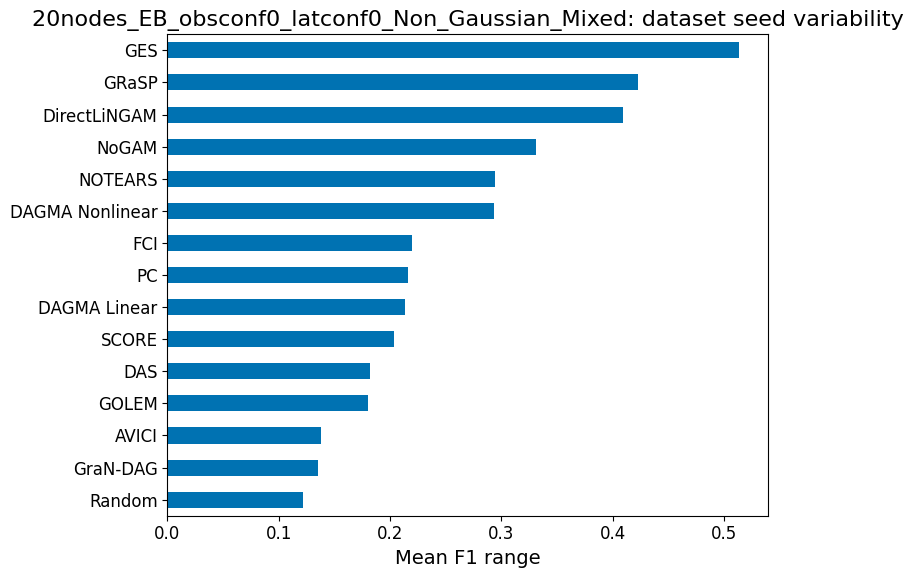

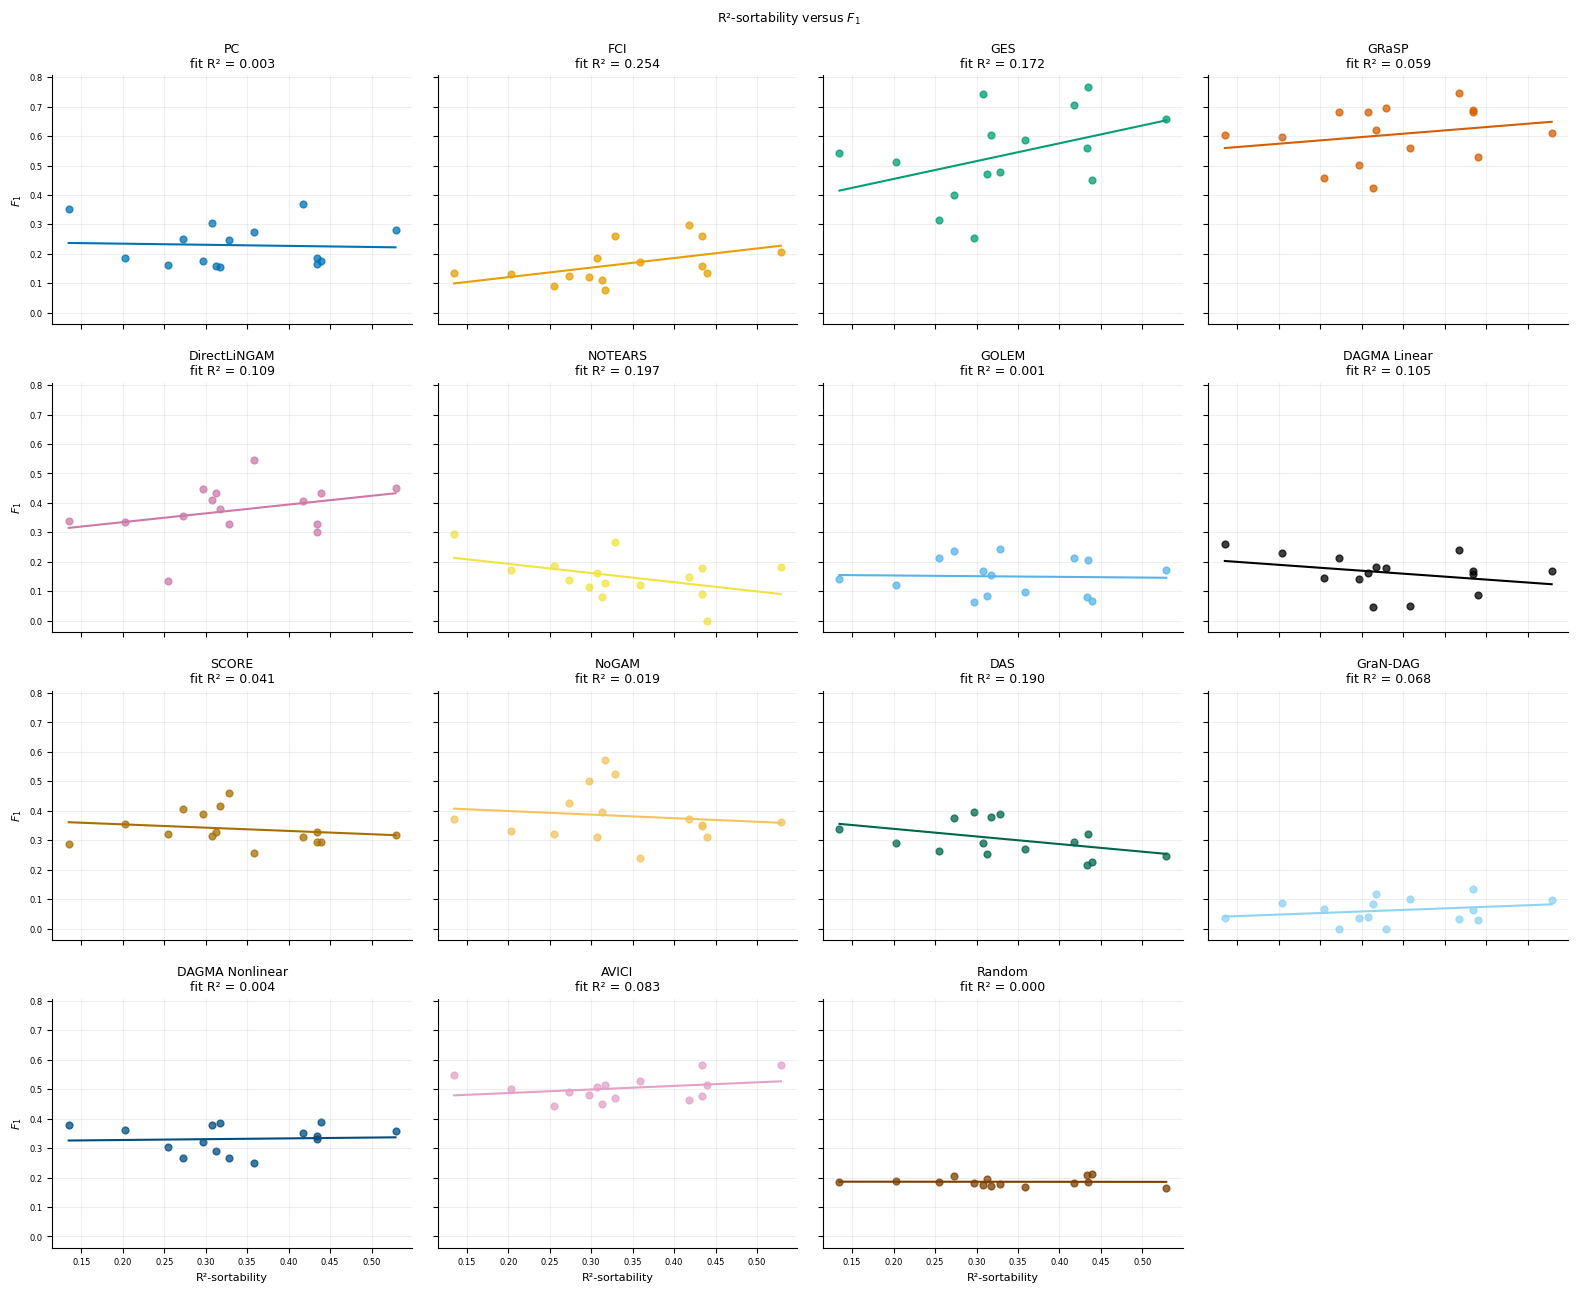

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,AVICI,0.582278,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
1,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Linear,0.170213,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
2,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Nonlinear,0.357541,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
3,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAS,0.247934,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
4,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DirectLiNGAM,0.450980,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
5,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,FCI,0.206897,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
6,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GES,0.658824,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
7,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GOLEM,0.171429,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
8,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GRaSP,0.610298,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
9,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GraNDAG,0.098361,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.374517,0.254826,259,97,0,66,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.703448,0.317241,145,102,0,46,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.492228,0.134715,193,95,0,26,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.528302,0.433962,265,140,0,115,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.448780,0.307317,205,92,0,63,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.637500,0.203125,320,204,0,65,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.522346,0.312849,358,187,0,112,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.538835,0.417476,412,222,0,172,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.605701,0.439430,421,255,0,185,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.288098,0.083000,0.121103,0.462718,0.297742,0.314286,0.253940
1,DAGMA_Linear,15,-0.324600,0.105365,-0.200269,0.229518,0.237837,-0.292857,0.289472
2,DAGMA_Nonlinear,15,0.060331,0.003640,0.027605,0.321958,0.830873,0.064286,0.819948
3,DAS,15,-0.436343,0.190396,-0.258641,0.390276,0.103937,-0.417857,0.121173
4,DirectLiNGAM,15,0.330463,0.109206,0.298590,0.274712,0.228972,0.264286,0.341174
5,FCI,15,0.504008,0.254024,0.325139,0.055675,0.055408,0.585714,0.021777
6,GES,15,0.414998,0.172223,0.605223,0.333314,0.124003,0.457143,0.086678
7,GOLEM,15,-0.038133,0.001454,-0.023500,0.158035,0.892672,-0.075000,0.790511
8,GRaSP,15,0.243340,0.059214,0.226278,0.528799,0.382153,0.328571,0.231810
9,GraNDAG,15,0.260692,0.067960,0.105608,0.026253,0.348022,0.155496,0.580009


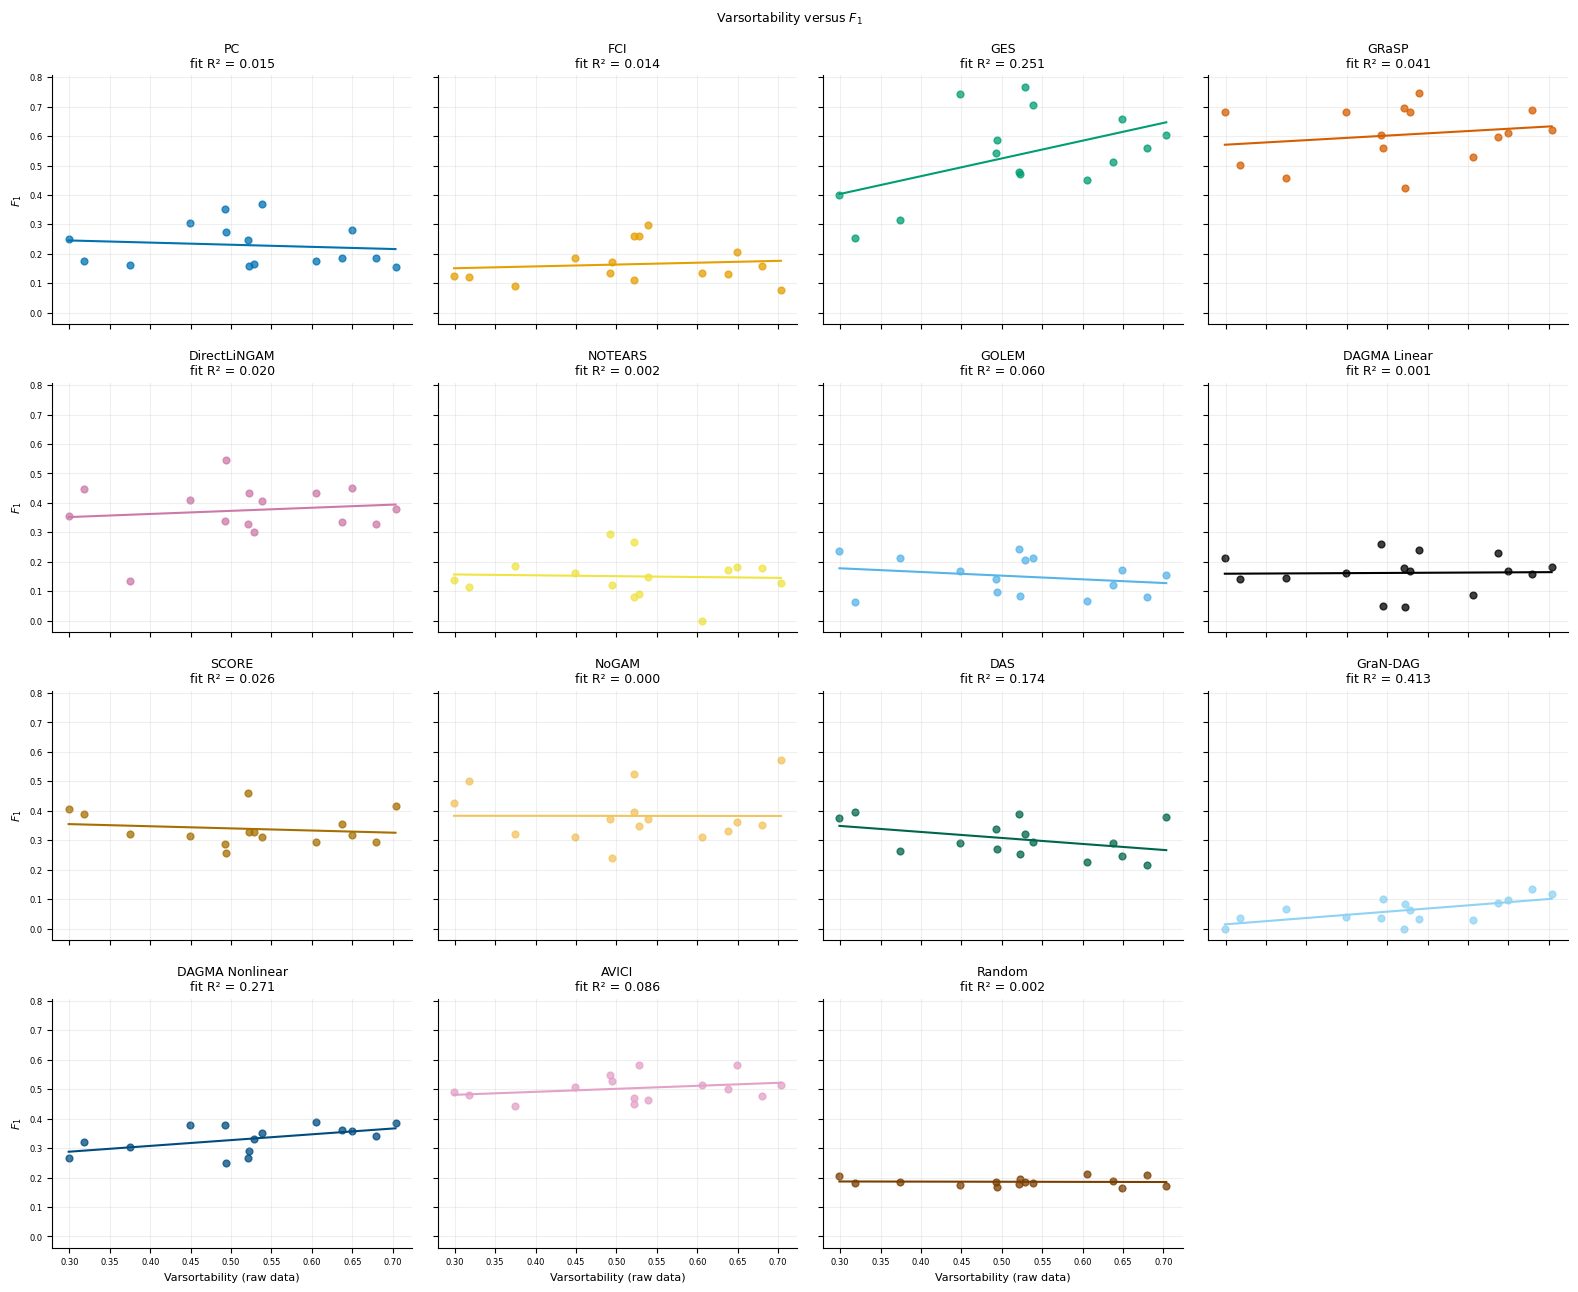

,dataset_seed,dataset,model,metric_value,completed_model_seeds,n_nodes,graph_type,obs_conf,lat_conf,noise,...,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,AVICI,0.582278,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
1,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Linear,0.170213,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
2,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Nonlinear,0.357541,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
3,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAS,0.247934,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
4,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DirectLiNGAM,0.450980,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
5,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,FCI,0.206897,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
6,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GES,0.658824,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
7,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GOLEM,0.171429,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
8,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GRaSP,0.610298,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
9,13,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GraNDAG,0.098361,15,20,EB,0,0,Non_Gaussian,...,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000


,dataset,dataset_seed,study,raw_variance_available,sample_path,varsortability,r2_sortability,n_paths,n_ordered_variance_paths,n_tied_variance_paths,n_ordered_r2_paths,n_tied_r2_paths,n_variables,n_observations
0,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,102,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.374517,0.254826,259,97,0,66,0,20,2000
1,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,13,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.649215,0.528796,191,124,0,101,0,20,2000
2,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,125,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.703448,0.317241,145,102,0,46,0,20,2000
3,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,158,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.492228,0.134715,193,95,0,26,0,20,2000
4,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,21,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.528302,0.433962,265,140,0,115,0,20,2000
5,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,222,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.448780,0.307317,205,92,0,63,0,20,2000
6,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,29,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.637500,0.203125,320,204,0,65,0,20,2000
7,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,32,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.522346,0.312849,358,187,0,112,0,20,2000
8,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,308,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.538835,0.417476,412,222,0,172,0,20,2000
9,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,402,benchmark,True,datasets/benchmark/20nodes_EB_obsconf0_latconf...,0.605701,0.439430,421,255,0,185,0,20,2000


""


,model,n_datasets,pearson_r,fit_r_squared,slope,intercept,p_value,spearman_rho,spearman_p_value
0,AVICI,15,0.293755,0.086292,0.101893,0.450337,0.287927,0.239286,0.390379
1,DAGMA_Linear,15,0.025903,0.000671,0.013187,0.155355,0.926990,0.125000,0.657136
2,DAGMA_Nonlinear,15,0.520931,0.271369,0.196686,0.228783,0.046465,0.489286,0.064160
3,DAS,15,-0.416563,0.173525,-0.203747,0.409498,0.122448,-0.414286,0.124715
4,DirectLiNGAM,15,0.141623,0.020057,0.105591,0.320042,0.614636,0.000000,1.000000
5,FCI,15,0.117494,0.013805,0.062545,0.132348,0.676660,0.164286,0.558497
6,GES,15,0.501213,0.251214,0.603163,0.222501,0.056999,0.460714,0.083933
7,GOLEM,15,-0.245576,0.060307,-0.124880,0.215187,0.377658,-0.221429,0.427714
8,GRaSP,15,0.201585,0.040637,0.154679,0.524263,0.471246,0.246429,0.375951
9,GraNDAG,15,0.642556,0.412878,0.214794,-0.050144,0.009785,0.564790,0.028260


In [3]:
for study, frame in [("benchmark", main)]:
    frame = frame.loc[frame.dataset.eq('20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed')].copy()
    values = sortability(frame, study)
    arms = (
        [("untuned", frame)]
        if study == "benchmark"
        else list(frame.groupby("arm", observed=True))
    )
    for arm, arm_frame in arms:
        for family, group in arm_frame.groupby("dataset", observed=True):
            family_output = output / study / "by_family" / family / arm
            family_output.mkdir(parents=True, exist_ok=True)
            data = th.visualization_data(group)
            # F1 and SHD, precision and recall retain dataset-level blocks.
            for metric in ("f1", "SHD", "precision", "recall"):
                blocks = (
                    group.loc[group.finished]
                    .groupby(["dataset_seed", "model"])[metric]
                    .mean()
                    .reset_index()
                )
                summary = (
                    blocks.groupby("model")[metric].agg(["mean", "std", "size"]).reset_index()
                )
                display(summary.head(20))
            for metric in ("f1", "SHD"):
                fig, _, _ = fv.plot_metric_boxplot_grid(
                    data,
                    [{"title": family, "datasets": family}],
                    metric=metric,
                    coverage_policy="all",
                    ncols=1,
                    figsize=(10, 7),
                    font_size=9,
                )
                fig.savefig(family_output / f"{metric}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
            # Stability only from recorded fits; invariant models remain zero.
            ok = group.loc[group.finished]
            model_range = (
                ok.groupby(["dataset_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            dataset_range = (
                ok.groupby(["model_seed", "model"])
                .f1.agg(lambda v: v.max() - v.min())
                .rename("f1_range")
                .reset_index()
            )
            for kind, table in [
                ("model_seed", model_range),
                ("dataset_seed", dataset_range),
            ]:
                display(table.head(20))
                summary = table.groupby("model").f1_range.mean().sort_values()
                fig, ax = plt.subplots(figsize=(8, 6))
                summary.rename(index=th.model_label).plot.barh(ax=ax)
                ax.set(
                    xlabel="Mean F1 range",
                    ylabel="",
                    title=f"{family}: {kind.replace('_', ' ')} variability",
                )
                fig.tight_layout()
                fig.savefig(family_output / f"{kind}_stability.pdf")
                display(fig)
                plt.close(fig)
            v = values.loc[values.dataset.eq(family)]
            for score in ("r2_sortability", "varsortability"):
                if v[score].notna().sum() < 3:
                    continue
                fig, _, details = fv.plot_varsortability_vs_f1(
                    data,
                    metric="f1",
                    datasets=family,
                    varsortability_values=v,
                    sortability=score,
                    coverage_policy="all",
                    columns=4,
                    include_r2_sort_regress=False,
                    obs_conf=None,
                    lat_conf=None,
                    font_size=8,
                    title_size=9,
                )
                fig.savefig(family_output / f"{score}.pdf", bbox_inches="tight")
                display(fig)
                plt.close(fig)
                for key, table in details.items():
                    if isinstance(table, pd.DataFrame):
                        display(table.head(20))
                blocks = (
                    ok.groupby(["dataset_seed", "model"])
                    .f1.mean()
                    .reset_index()
                    .merge(v, on="dataset_seed")
                )
                for model, g in blocks.groupby("model"):
                    valid = g[["f1", score]].dropna()
                    constant = valid.nunique().min() < 2
                    r = (
                        None
                        if len(valid) < 3 or constant
                        else spearmanr(valid[score], valid.f1)
                    )
                    correlations.append(
                        dict(
                            study=study,
                            arm=arm,
                            dataset=family,
                            model=model,
                            sortability=score,
                            n_pairs=len(valid),
                            rho=np.nan if r is None else r.statistic,
                            pvalue=np.nan if r is None else r.pvalue,
                            status="constant_or_insufficient" if r is None else "estimated",
                        )
                    )


In [4]:
corr = pd.DataFrame(correlations)
if len(corr):
    from statistical_methods import holm

    corr["pvalue_holm"] = np.nan
    valid = corr.pvalue.notna()
    corr.loc[valid, "pvalue_holm"] = (
        corr.loc[valid]
        .groupby(["study", "arm", "sortability"])
        .pvalue.transform(lambda p: holm(p))
    )
display(corr.head(20))


,study,arm,dataset,model,sortability,n_pairs,rho,pvalue,status,pvalue_holm
0,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,AVICI,r2_sortability,15,0.314286,0.253940,estimated,1.000000
1,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Linear,r2_sortability,15,-0.292857,0.289472,estimated,1.000000
2,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAGMA_Nonlinear,r2_sortability,15,0.064286,0.819948,estimated,1.000000
3,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DAS,r2_sortability,15,-0.417857,0.121173,estimated,1.000000
4,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,DirectLiNGAM,r2_sortability,15,0.264286,0.341174,estimated,1.000000
5,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,FCI,r2_sortability,15,0.585714,0.021777,estimated,0.326648
6,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GES,r2_sortability,15,0.457143,0.086678,estimated,1.000000
7,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GOLEM,r2_sortability,15,-0.075000,0.790511,estimated,1.000000
8,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GRaSP,r2_sortability,15,0.328571,0.231810,estimated,1.000000
9,benchmark,untuned,20nodes_EB_obsconf0_latconf0_Non_Gaussian_Mixed,GraNDAG,r2_sortability,15,0.155496,0.580009,estimated,1.000000
